In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
df_yield = pd.read_csv("01_raw_usda_nass_corn_yield_2000_2025.csv")
df_precip = pd.read_csv("02_raw_noaa_ncei_county_precipitation_2000_2025.csv")
df_temp = pd.read_csv("03_raw_noaa_ncei_county_temperature_2000_2025.csv")
df_pdsi = pd.read_csv("04_raw_noaa_ncei_county_drought_pdsi_2000_2025.csv")

In [20]:
df_yield.describe()

,Year,Week Ending,State ANSI,Ag District Code,County ANSI,Zip Code,Region,watershed_code,Watershed,Value,CV (%),corn_yield_bu_acre,state_fips,county_ansi,fips,year
count,2417.000000,0.0,2417.0,2417.000000,2417.000000,0.0,0.0,2417.0,0.0,2417.000000,489.000000,2417.000000,2417.0,2417.000000,2417.000000,2417.000000
mean,2011.818784,NaN,17.0,51.315681,103.416218,NaN,NaN,0.0,NaN,168.585023,2.765031,168.585023,17.0,103.416218,17103.416218,2011.818784
std,7.365478,NaN,0.0,26.117540,58.937057,NaN,NaN,0.0,NaN,36.133461,1.159911,36.133461,0.0,58.937057,58.937057,7.365478
min,2000.000000,NaN,17.0,10.000000,1.000000,NaN,NaN,0.0,NaN,19.000000,0.700000,19.000000,17.0,1.000000,17001.000000,2000.000000
25%,2005.000000,NaN,17.0,30.000000,53.000000,NaN,NaN,0.0,NaN,147.000000,1.900000,147.000000,17.0,53.000000,17053.000000,2005.000000
50%,2011.000000,NaN,17.0,60.000000,105.000000,NaN,NaN,0.0,NaN,171.000000,2.500000,171.000000,17.0,105.000000,17105.000000,2011.000000
75%,2018.000000,NaN,17.0,70.000000,155.000000,NaN,NaN,0.0,NaN,192.700000,3.300000,192.700000,17.0,155.000000,17155.000000,2018.000000
max,2025.000000,NaN,17.0,90.000000,203.000000,NaN,NaN,0.0,NaN,253.600000,8.700000,253.600000,17.0,203.000000,17203.000000,2025.000000


In [21]:
df_temp.describe()

,fips,year,mean_temp_F_Jan,mean_temp_F_Feb,mean_temp_F_Mar,mean_temp_F_Apr,mean_temp_F_May,mean_temp_F_Jun,mean_temp_F_Jul,mean_temp_F_Aug,mean_temp_F_Sep,mean_temp_F_Oct,mean_temp_F_Nov,mean_temp_F_Dec
count,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.00000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000
mean,17016.000000,2012.500000,18.870913,20.780048,29.762019,41.496875,52.884615,61.68149,67.731731,66.378125,59.030769,47.898077,36.366587,25.190625
std,9.230646,7.509031,5.768919,5.238763,4.816133,3.099314,2.673287,2.39367,2.672737,2.394004,2.566948,3.312648,3.709378,4.976410
min,17001.000000,2000.000000,2.300000,1.300000,13.800000,32.300000,44.900000,55.90000,60.800000,59.900000,52.600000,38.600000,25.600000,12.000000
25%,17008.500000,2006.000000,15.000000,17.475000,26.900000,39.775000,51.200000,60.00000,65.775000,64.800000,57.275000,45.800000,33.800000,21.500000
50%,17016.000000,2012.500000,19.300000,21.600000,30.100000,41.800000,53.100000,61.70000,68.000000,66.500000,59.100000,48.050000,36.500000,25.700000
75%,17023.500000,2019.000000,23.500000,24.500000,33.200000,43.800000,54.800000,63.30000,69.900000,68.100000,60.900000,50.100000,39.200000,28.700000
max,17031.000000,2025.000000,30.800000,29.500000,40.800000,48.700000,60.100000,68.60000,73.400000,71.800000,64.900000,55.900000,42.800000,36.200000


In [22]:
df_precip.describe()

,fips,year,precip_in_Jan,precip_in_Feb,precip_in_Mar,precip_in_Apr,precip_in_May,precip_in_Jun,precip_in_Jul,precip_in_Aug,precip_in_Sep,precip_in_Oct,precip_in_Nov,precip_in_Dec
count,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.00000,416.000000
mean,17016.000000,2012.500000,3.126346,2.966875,3.617957,4.135673,3.845120,4.448245,4.006755,3.809687,3.647188,5.221875,4.13262,4.792764
std,9.230646,7.509031,1.418208,1.162123,1.869312,1.743344,1.792558,1.916399,1.768519,1.686873,1.856229,2.551265,1.56585,1.379383
min,17001.000000,2000.000000,0.370000,0.600000,1.050000,0.740000,0.730000,0.880000,1.110000,0.570000,0.620000,1.120000,0.86000,1.340000
25%,17008.500000,2006.000000,2.185000,2.340000,2.317500,2.840000,2.417500,3.050000,2.740000,2.547500,2.282500,3.472500,2.91000,3.807500
50%,17016.000000,2012.500000,3.015000,2.875000,3.295000,3.975000,3.705000,3.870000,3.640000,3.575000,3.380000,5.155000,4.00000,4.730000
75%,17023.500000,2019.000000,3.872500,3.445000,4.330000,5.240000,5.062500,5.625000,4.997500,4.950000,4.832500,6.492500,5.15250,5.612500
max,17031.000000,2025.000000,8.210000,8.730000,13.560000,9.930000,13.590000,10.470000,11.070000,8.380000,10.780000,15.880000,10.03000,9.840000


In [23]:
df_pdsi.describe()

,fips,year,pdsi_drought_idx_Jan,pdsi_drought_idx_Feb,pdsi_drought_idx_Mar,pdsi_drought_idx_Apr,pdsi_drought_idx_May,pdsi_drought_idx_Jun,pdsi_drought_idx_Jul,pdsi_drought_idx_Aug,pdsi_drought_idx_Sep,pdsi_drought_idx_Oct,pdsi_drought_idx_Nov,pdsi_drought_idx_Dec
count,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000,416.000000
mean,17016.000000,2012.500000,0.612668,0.493389,0.513990,0.507356,0.542091,0.756995,0.888438,0.895168,0.735721,1.194159,0.623125,0.908918
std,9.230646,7.509031,2.379260,2.082096,2.125685,1.993719,1.887642,2.031112,2.089888,2.379873,2.345826,2.547277,2.621353,2.516983
min,17001.000000,2000.000000,-6.130000,-5.230000,-4.370000,-3.670000,-3.700000,-4.020000,-4.200000,-4.860000,-5.030000,-5.660000,-6.360000,-6.480000
25%,17008.500000,2006.000000,-1.010000,-0.982500,-1.155000,-1.205000,-0.960000,-0.902500,-0.860000,-1.097500,-1.175000,-0.845000,-1.192500,-0.680000
50%,17016.000000,2012.500000,0.450000,0.470000,0.570000,0.605000,0.660000,0.975000,1.070000,1.105000,0.765000,1.430000,0.655000,0.955000
75%,17023.500000,2019.000000,2.300000,2.040000,1.997500,2.042500,1.925000,2.435000,2.292500,2.680000,2.457500,2.992500,2.557500,2.842500
max,17031.000000,2025.000000,6.800000,6.180000,7.820000,6.110000,4.810000,5.690000,6.050000,6.720000,7.280000,6.630000,6.360000,6.590000


In [24]:
#Clean yield Data
# Drop columns that contain ANY missing/blank values
df_yield = df_yield.dropna(axis=1, how='any')
# Drop columns filled entirely with zeros
df_yield = df_yield.loc[:, (df_yield != 0).any(axis=0)]
display(df_yield)

,Program,Year,Period,Geo Level,State,State ANSI,Ag District,Ag District Code,County,County ANSI,...,Data Item,Domain,Domain Category,Value,corn_yield_bu_acre,state_fips,county_ansi,fips,year,county_fips_year
0,SURVEY,2025,YEAR,COUNTY,ILLINOIS,17,CENTRAL,40,MACON,115.0,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,238.6,238.6,17,115,17115,2025,17115_2025
1,SURVEY,2025,YEAR,COUNTY,ILLINOIS,17,CENTRAL,40,MARSHALL,123.0,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,239.9,239.9,17,123,17123,2025,17123_2025
2,SURVEY,2025,YEAR,COUNTY,ILLINOIS,17,CENTRAL,40,MASON,125.0,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,215.3,215.3,17,125,17125,2025,17125_2025
3,SURVEY,2025,YEAR,COUNTY,ILLINOIS,17,CENTRAL,40,MCLEAN,113.0,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,243.1,243.1,17,113,17113,2025,17113_2025
4,SURVEY,2025,YEAR,COUNTY,ILLINOIS,17,CENTRAL,40,MENARD,129.0,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,229.2,229.2,17,129,17129,2025,17129_2025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2412,SURVEY,2000,YEAR,COUNTY,ILLINOIS,17,WEST SOUTHWEST,60,MONTGOMERY,135.0,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,173.0,173.0,17,135,17135,2000,17135_2000
2413,SURVEY,2000,YEAR,COUNTY,ILLINOIS,17,WEST SOUTHWEST,60,MORGAN,137.0,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,168.0,168.0,17,137,17137,2000,17137_2000
2414,SURVEY,2000,YEAR,COUNTY,ILLINOIS,17,WEST SOUTHWEST,60,PIKE,149.0,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,174.0,174.0,17,149,17149,2000,17149_2000
2415,SURVEY,2000,YEAR,COUNTY,ILLINOIS,17,WEST SOUTHWEST,60,SANGAMON,167.0,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",TOTAL,NOT SPECIFIED,174.0,174.0,17,167,17167,2000,17167_2000


In [25]:
#Clean Precipitation Data
#Drop columns with blanks
df_precip = df_precip.dropna(axis=1, how='any')
# Drop columns filled entirely with zeros
df_precip = df_precip.loc[:, (df_precip != 0).any(axis=0)]
display(df_precip)

,fips,year,county_fips_year,noaa_element,precip_in_Jan,precip_in_Feb,precip_in_Mar,precip_in_Apr,precip_in_May,precip_in_Jun,precip_in_Jul,precip_in_Aug,precip_in_Sep,precip_in_Oct,precip_in_Nov,precip_in_Dec
0,17001,2000,17001_2000,precip_in,3.62,3.11,4.16,5.73,4.56,2.67,5.83,2.15,1.63,3.45,3.88,4.97
1,17001,2001,17001_2001,precip_in,1.38,3.07,6.94,1.17,1.51,5.06,3.20,0.78,3.49,1.46,3.41,2.38
2,17001,2002,17001_2002,precip_in,2.69,3.28,4.09,5.16,3.98,5.31,2.00,1.25,4.39,3.71,4.87,3.64
3,17001,2003,17001_2003,precip_in,1.61,2.57,3.15,1.97,3.42,2.25,2.23,3.80,5.41,7.76,4.19,6.61
4,17001,2004,17001_2004,precip_in,0.41,1.84,1.23,4.69,4.90,2.14,4.20,6.28,2.65,2.15,4.50,4.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
411,17031,2021,17031_2021,precip_in,2.16,2.94,2.18,3.69,2.86,1.00,11.07,3.53,4.82,7.34,3.10,4.00
412,17031,2022,17031_2022,precip_in,2.52,4.16,3.07,4.70,1.80,2.72,2.78,6.60,4.83,5.52,3.78,6.09
413,17031,2023,17031_2023,precip_in,7.29,1.52,3.75,4.35,5.65,5.94,7.37,7.37,4.40,3.11,2.99,7.50
414,17031,2024,17031_2024,precip_in,6.94,0.89,10.00,4.25,2.64,3.15,2.47,5.33,1.92,1.83,2.79,4.78


In [26]:
#Clean Temperature Data
df_temp = df_temp.dropna(axis=1, how='any')
df_temp = df_temp.loc[:, (df_temp != 0).any(axis=0)]
display(df_temp)

,fips,year,county_fips_year,noaa_element,mean_temp_F_Jan,mean_temp_F_Feb,mean_temp_F_Mar,mean_temp_F_Apr,mean_temp_F_May,mean_temp_F_Jun,mean_temp_F_Jul,mean_temp_F_Aug,mean_temp_F_Sep,mean_temp_F_Oct,mean_temp_F_Nov,mean_temp_F_Dec
0,17001,2000,17001_2000,mean_temp_F,17.3,22.4,36.0,42.0,52.1,62.4,64.6,65.3,56.8,47.1,38.2,21.3
1,17001,2001,17001_2001,mean_temp_F,17.4,19.9,27.8,41.2,55.9,66.0,66.1,70.2,60.3,48.7,40.0,31.7
2,17001,2002,17001_2002,mean_temp_F,26.0,24.8,31.8,43.6,51.8,61.0,68.9,69.9,62.2,44.8,34.0,24.3
3,17001,2003,17001_2003,mean_temp_F,13.2,16.9,28.2,39.7,51.8,63.4,69.1,68.5,60.0,46.5,38.4,26.3
4,17001,2004,17001_2004,mean_temp_F,11.1,22.3,33.0,42.5,54.8,60.2,66.6,66.9,59.0,47.7,37.0,23.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
411,17031,2021,17031_2021,mean_temp_F,25.9,22.9,34.2,45.2,55.9,67.9,67.2,70.5,62.6,52.7,38.3,30.7
412,17031,2022,17031_2022,mean_temp_F,18.0,25.5,34.1,44.7,57.4,63.1,72.0,71.8,59.5,50.2,42.2,30.9
413,17031,2023,17031_2023,mean_temp_F,30.8,25.7,34.3,45.3,55.2,62.2,72.0,66.5,62.9,53.8,35.6,34.3
414,17031,2024,17031_2024,mean_temp_F,26.0,28.9,37.1,43.7,56.7,67.0,73.4,67.8,60.9,49.7,42.3,27.5


In [27]:
# Clean Drought (PDSI) Data
df_pdsi = df_pdsi.dropna(axis=1, how='any')
df_pdsi = df_pdsi.loc[:, (df_pdsi != 0).any(axis=0)]
display(df_pdsi)

,fips,year,county_fips_year,noaa_element,pdsi_drought_idx_Jan,pdsi_drought_idx_Feb,pdsi_drought_idx_Mar,pdsi_drought_idx_Apr,pdsi_drought_idx_May,pdsi_drought_idx_Jun,pdsi_drought_idx_Jul,pdsi_drought_idx_Aug,pdsi_drought_idx_Sep,pdsi_drought_idx_Oct,pdsi_drought_idx_Nov,pdsi_drought_idx_Dec
0,17001,2000,17001_2000,pdsi_drought_idx,-1.05,-1.04,-0.93,0.66,0.93,0.54,1.50,-0.23,-0.78,-0.89,-1.17,-0.78
1,17001,2001,17001_2001,pdsi_drought_idx,-1.49,-1.44,1.13,-1.08,-1.72,-1.36,-1.28,-2.32,-2.30,-3.14,-3.69,-4.11
2,17001,2002,17001_2002,pdsi_drought_idx,-4.02,-3.63,-3.13,-2.45,-2.02,-1.13,-1.51,-2.35,-2.07,-1.97,-1.73,-1.71
3,17001,2003,17001_2003,pdsi_drought_idx,-2.25,-2.33,-2.30,-2.77,-2.48,-2.71,-3.05,-2.82,0.54,1.81,1.44,2.09
4,17001,2004,17001_2004,pdsi_drought_idx,-1.12,-1.63,-2.39,0.23,0.56,0.10,0.37,1.52,-0.17,-0.57,-0.59,-0.48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
411,17031,2021,17031_2021,pdsi_drought_idx,-1.61,-1.62,-2.10,-2.10,-2.22,-3.13,2.90,2.92,3.08,4.16,-0.46,-0.45
412,17031,2022,17031_2022,pdsi_drought_idx,-0.76,-0.35,-0.65,-0.41,-1.08,-1.40,-1.80,1.01,1.34,1.93,1.38,1.87
413,17031,2023,17031_2023,pdsi_drought_idx,2.89,1.84,1.53,1.39,1.78,2.53,3.94,5.59,5.43,4.78,3.87,4.50
414,17031,2024,17031_2024,pdsi_drought_idx,5.14,3.59,5.14,4.66,-0.43,-0.73,-1.29,-0.51,-1.11,-1.92,-2.78,-2.53


In [28]:
# Drop redundant tracking columns from weather datasets to prevent duplicates
cols_to_drop = ['fips', 'year', 'noaa_element']
df_precip = df_precip.drop(columns=cols_to_drop, errors='ignore')
df_temp = df_temp.drop(columns=cols_to_drop, errors='ignore')
df_pdsi = df_pdsi.drop(columns=cols_to_drop, errors='ignore')

In [29]:
#Merging
# Sequential Inner Join
merged_data = pd.merge(df_yield, df_precip, on='county_fips_year', how='inner')
merged_data = pd.merge(merged_data, df_temp, on='county_fips_year', how='inner')
merged_data = pd.merge(merged_data, df_pdsi, on='county_fips_year', how='inner')
display(merged_data)

,Program,Year,Period,Geo Level,State,State ANSI,Ag District,Ag District Code,County,County ANSI,...,pdsi_drought_idx_Mar,pdsi_drought_idx_Apr,pdsi_drought_idx_May,pdsi_drought_idx_Jun,pdsi_drought_idx_Jul,pdsi_drought_idx_Aug,pdsi_drought_idx_Sep,pdsi_drought_idx_Oct,pdsi_drought_idx_Nov,pdsi_drought_idx_Dec
0,SURVEY,2025,YEAR,COUNTY,ILLINOIS,17,EAST SOUTHEAST,70,CLARK,23.0,...,-2.07,-1.61,-0.62,-0.79,-1.32,-2.26,-2.54,-2.92,-3.64,-3.46
1,SURVEY,2025,YEAR,COUNTY,ILLINOIS,17,EAST SOUTHEAST,70,CLAY,25.0,...,0.46,0.55,1.06,1.08,-0.96,-1.95,-2.68,-2.90,-3.42,-3.03
2,SURVEY,2025,YEAR,COUNTY,ILLINOIS,17,EAST SOUTHEAST,70,COLES,29.0,...,-2.39,-1.20,-0.88,-0.93,-1.51,-2.16,-2.72,-3.14,-3.46,-3.20
3,SURVEY,2025,YEAR,COUNTY,ILLINOIS,17,NORTHEAST,20,BOONE,7.0,...,0.35,0.11,1.11,-0.09,-0.95,-2.00,-2.73,-2.78,-3.23,-2.95
4,SURVEY,2025,YEAR,COUNTY,ILLINOIS,17,NORTHWEST,10,BUREAU,11.0,...,-1.80,-1.52,-0.80,-0.88,-1.58,-2.29,-2.47,-2.74,-3.51,-3.17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
365,SURVEY,2000,YEAR,COUNTY,ILLINOIS,17,WEST,30,BROWN,9.0,...,0.68,1.48,1.64,-0.35,-0.33,-0.79,-1.42,-1.32,-1.85,-1.63
366,SURVEY,2000,YEAR,COUNTY,ILLINOIS,17,WEST SOUTHWEST,60,BOND,5.0,...,0.03,0.69,0.68,0.34,1.47,-0.07,-0.46,-0.51,-0.63,-0.36
367,SURVEY,2000,YEAR,COUNTY,ILLINOIS,17,WEST SOUTHWEST,60,CALHOUN,13.0,...,-1.01,0.62,0.75,0.60,1.34,-0.27,-0.55,-0.54,-0.97,-0.94
368,SURVEY,2000,YEAR,COUNTY,ILLINOIS,17,WEST SOUTHWEST,60,CASS,17.0,...,0.98,2.04,2.56,1.81,2.28,-0.22,-0.70,-0.89,-1.07,-0.56


In [30]:
# Analytical Feature Engineering
# Calculate suitability metrics using standard arithmetic
merged_data['Summer_Precip_Total'] = merged_data['precip_in_Jun'] + merged_data['precip_in_Jul'] + merged_data['precip_in_Aug']
merged_data['Summer_Temp_Avg'] = (merged_data['mean_temp_F_Jun'] + merged_data['mean_temp_F_Jul'] + merged_data['mean_temp_F_Aug']) / 3
print(merged_data['Summer_Precip_Total'])
print(merged_data['Summer_Temp_Avg'])

0       5.95
1       8.33
2       6.68
3       8.08
4       6.64
       ...  
365     7.52
366    11.07
367     9.80
368    10.62
369     8.81
Name: Summer_Precip_Total, Length: 370, dtype: float64
0      67.900000
1      64.166667
2      65.366667
3      63.433333
4      68.000000
         ...    
365    63.833333
366    64.466667
367    63.100000
368    61.500000
369    60.500000
Name: Summer_Temp_Avg, Length: 370, dtype: float64


In [31]:
# Verify that the dataset has exactly 0 empty places left
total_missing = merged_data.isna().sum().sum()
print(total_missing)

0


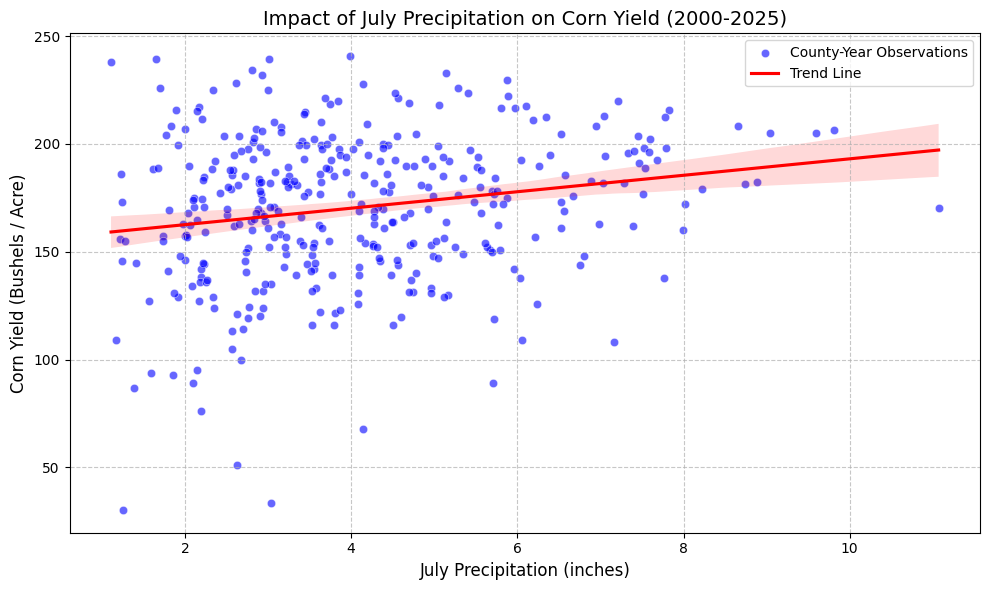

In [32]:
#Data Visualization
#Scatter Plot
plt.figure(figsize=(10, 6))
# Let's look at July Precipitation vs Corn Yield, as July is critical for corn pollination
sns.scatterplot(data=merged_data, x='precip_in_Jul', y='corn_yield_bu_acre', alpha=0.6, color='blue', label='County-Year Observations')
sns.regplot(data=merged_data, x='precip_in_Jul', y='corn_yield_bu_acre', scatter=False, color='red', label='Trend Line')
plt.title('Impact of July Precipitation on Corn Yield (2000-2025)', fontsize=14)
plt.xlabel('July Precipitation (inches)', fontsize=12)
plt.ylabel('Corn Yield (Bushels / Acre)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

[{'County': 'CARROLL', 'corn_yield_bu_acre': 197.26153846153846}, {'County': 'BUREAU', 'corn_yield_bu_acre': 189.53461538461536}, {'County': 'CHRISTIAN', 'corn_yield_bu_acre': 189.4375}, {'County': 'CHAMPAIGN', 'corn_yield_bu_acre': 183.0}, {'County': 'CASS', 'corn_yield_bu_acre': 182.92916666666667}, {'County': 'COLES', 'corn_yield_bu_acre': 182.2541666666667}, {'County': 'BOONE', 'corn_yield_bu_acre': 179.22400000000002}, {'County': 'CLARK', 'corn_yield_bu_acre': 168.36521739130436}, {'County': 'ADAMS', 'corn_yield_bu_acre': 165.54583333333332}, {'County': 'BROWN', 'corn_yield_bu_acre': 161.5875}, {'County': 'CALHOUN', 'corn_yield_bu_acre': 158.79090909090908}, {'County': 'CLINTON', 'corn_yield_bu_acre': 153.84}, {'County': 'ALEXANDER', 'corn_yield_bu_acre': 152.06315789473683}, {'County': 'BOND', 'corn_yield_bu_acre': 150.6818181818182}, {'County': 'CLAY', 'corn_yield_bu_acre': 148.55200000000002}, {'County': 'COOK', 'corn_yield_bu_acre': 141.07692307692307}]


/tmp/ipykernel_899/3575488542.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=county_yield, x='corn_yield_bu_acre', y='County', palette='viridis')


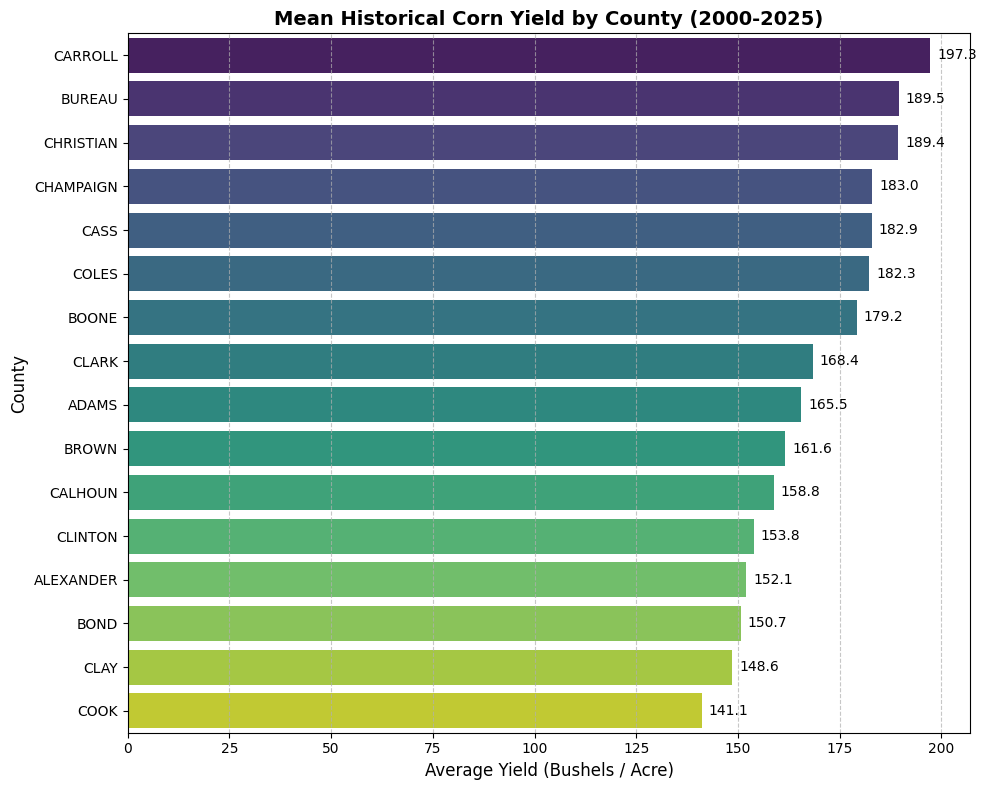

In [33]:
#Bar Chart for 16 Counties
county_yield = merged_data.groupby('County')['corn_yield_bu_acre'].mean().reset_index()
county_yield = county_yield.sort_values(by='corn_yield_bu_acre', ascending=False)
print(county_yield.to_dict('records'))
plt.figure(figsize=(10, 8))
ax = sns.barplot(data=county_yield, x='corn_yield_bu_acre', y='County', palette='viridis')
plt.title('Mean Historical Corn Yield by County (2000-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Average Yield (Bushels / Acre)', fontsize=12)
plt.ylabel('County', fontsize=12)
for p in ax.patches:
    ax.annotate(f"{p.get_width():.1f}",
                (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                fontsize=10, color='black',
                xytext=(5, 0), textcoords='offset points')

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

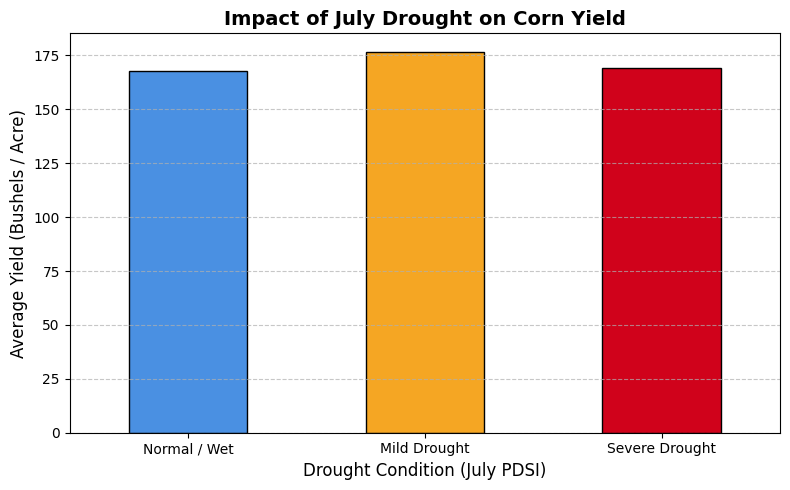

In [34]:
#Bar Chart
def get_drought_level(pdsi):
    if pdsi < -2.0:
        return "Severe Drought"
    elif pdsi < 0:
        return "Mild Drought"
    else:
        return "Normal / Wet"

merged_data['Drought_Level'] = merged_data['pdsi_drought_idx_Jul'].apply(get_drought_level)
#Calculate the average yield for each category
avg_yields = merged_data.groupby('Drought_Level')['corn_yield_bu_acre'].mean()
# Put them in order from wettest to driest
avg_yields = avg_yields[["Normal / Wet", "Mild Drought", "Severe Drought"]]
#Make a simple bar chart
plt.figure(figsize=(8, 5))
avg_yields.plot(kind='bar', color=['#4A90E2', '#F5A623', '#D0021B'], edgecolor='black')
plt.title('Impact of July Drought on Corn Yield', fontsize=14, fontweight='bold')
plt.xlabel('Drought Condition (July PDSI)', fontsize=12)
plt.ylabel('Average Yield (Bushels / Acre)', fontsize=12)
plt.xticks(rotation=0) # Keeps the text labels flat instead of tilted
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()